In [18]:
import enum, random

class Kid(enum.Enum):
    boy = 0
    girl = 1
def random_kid():
    return random.choice([Kid.boy, Kid.girl])

both_girl = 0
older_girl = 0
at_least_one_girl = 0

random.seed(1234)
for _ in range(10_000):
    young_kid= random_kid()
    older_kid = random_kid()
    if young_kid == Kid.girl and older_kid == Kid.boy:
        both_girl += 1
    if older_kid == Kid.girl:
        older_girl += 1
    if older_kid == Kid.girl or young_kid == Kid.girl:
        at_least_one_girl += 1
print('P(both|older)', both_girl/older_girl)
print('P(both|at least one girl)', both_girl/at_least_one_girl)

P(both|older) 0.5014022435897436
P(both|at least one girl) 0.3339559706470981


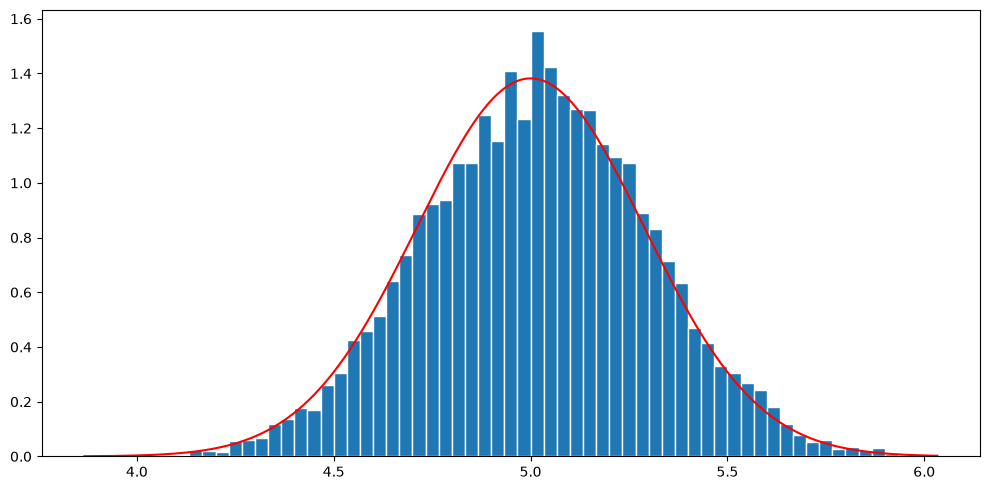

In [73]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats
# sprawdzenie centralego tw graniczego za pomoca rozladu bernuliego(n,p)

def bernoulli_trial(p):
    return 1 if p >= random.uniform(0,1) else 0

def bernoulli_realization(n,p):
    return np.sum([bernoulli_trial(p) for _ in range(n)]).item()

N_val = 30
def mean_of_bernoulli_realizations(n=10,p=1/2, N=N_val):
    return np.mean([bernoulli_realization(n,p) for _ in range(N)]).item()

num_of_realizations = 10_000
X = [mean_of_bernoulli_realizations() for _ in range(num_of_realizations)]

krok = 1 / N_val 

zoptymalizowane_przedzialy = np.arange(min(X), max(X), krok)
mu = 10*1/2
sigma = ((10* 0.5 * (1-0.5))/ N_val) **0.5 
ax_x = np.linspace(min(X), max(X), 1_000)
ax_y = scipy.stats.norm.pdf(ax_x, mu, sigma)

plt.figure(figsize=(10,5))
plt.hist(X,edgecolor = "white", bins=zoptymalizowane_przedzialy, density=True)
plt.plot(ax_x, ax_y, color = 'red')
plt.tight_layout()
plt.show()
